In [35]:
"""RPA resistance model: one parameter set, one time axis.

    dA/dt = alpha * (mu - B)                       integral feedback on setpoint
    dB/dt = beta1*(1 - e(t))*A - beta2*B           therapy blocks the A->B arm
    dC/dt = C * (c1 - c2 * max(mu - B, 0))         one-sided effect on the tumor

A = compensatory angiogenic factors, B = blood vessel density, C = tumor size.

Treatment enters as a fractional block e in [0,1) of the A->B arm, matching the
arrow the drug is drawn on. Adaptation is untouched (B* = mu comes from
dA/dt = 0), but A* = beta2*mu/(beta1*(1-e)) rises to compensate. During
treatment the loop gain is alpha*beta1*(1-e), so
    omega_n = sqrt(alpha*beta1*(1-e)),  zeta = beta2 / (2*omega_n),
and the drop rate at onset is exactly -beta2*e.
"""
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

PLOTS_DIR = Path("../plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """
    Save a matplotlib figure to the PLOTS_DIR as a PDF file.

    Args:
        fig: The matplotlib figure object to save.
        name: The filename (without extension) or with .pdf extension.
    """
    # Ensure the filename ends with .pdf
    if not name.lower().endswith(".pdf"):
        name = f"{name}.pdf"
    save_path = PLOTS_DIR / name
    fig.savefig(save_path, format="pdf", bbox_inches="tight")
    print(f"Figure saved to {save_path}")


# --- shared parameters ----------------------------------------------------
# beta2 = 6 with alpha = 16 keeps zeta between 0.84 and 1.37 for doses e in
# [0.1, 0.7]: no visible overshoot, and every curve back at setpoint inside 8 weeks.
alpha, beta1, beta2, mu = 16.0, 1.0, 6.0, 1.0
t_rx, e = 2.0, 0.40           # treatment start (weeks) and fractional block
c1, c2 = 1.04, 11.5           # tumor growth rate, sensitivity to vessel deficit
T = 8.0                       # shared time axis, weeks


def rhs(t, y):
    A, B, C = y
    gain = beta1 * (1 - (e if t >= t_rx else 0.0))
    return [alpha * (mu - B),
            gain * A - beta2 * B,
            C * (c1 - c2 * max(mu - B, 0.0))]


sol = solve_ivp(rhs, [0, T], [beta2 * mu / beta1, mu, 1.0],
                max_step=0.005, dense_output=True)
t = np.linspace(0, T, 1600)
A, B, C = sol.sol(t)


def style(ax):
    ax.axvspan(t_rx, T, color='0.93', zorder=0)     # treatment window
    ax.set_xlim(0, T)
    ax.set_xticks(range(int(T) + 1))
    ax.set_xlabel('time (weeks)')
    ax.spines[['top', 'right']].set_visible(False)

Figure saved to ../plots/Figure1_C.pdf


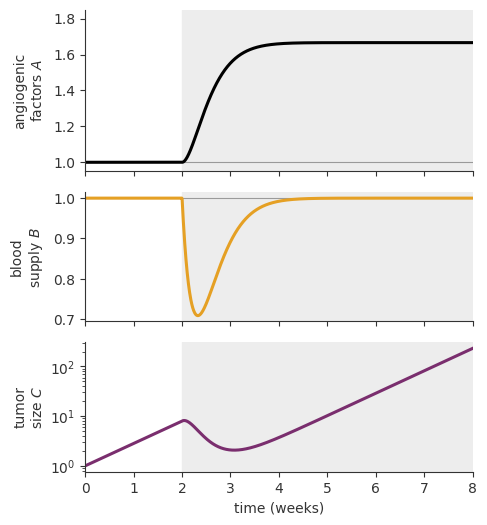

In [36]:
# --- Figure 1C: the adapting variables and the tumor ----------------------
# --- palette: one color per model variable, used in every panel ------------
FEEDBACK = "black"                       # A: compensatory angiogenic factors
REGULATED = "#e5a024"                      # B: blood vessel density / oxygen
TUMOR = "#7A2E6E"                          # C: tumor size
REF = "#9A9A9A"                            # reference lines

plt.rcParams.update({"pdf.fonttype": 42})  # editable text in Illustrator

A_rel = A / (beta2 * mu / beta1)   # A relative to its pre-treatment steady state

fig, (axA, axB, axC) = plt.subplots(
    3, 1, figsize=(5, 6), sharex=True,
    gridspec_kw=dict(height_ratios=[1.25, 1, 1], hspace=0.15),
)
for ax in (axA, axB, axC):
    style(ax)
for ax in (axA, axB):
    ax.set_xlabel("")

# A: compensatory factors
axA.axhline(1.0, color=REF, lw=0.8, zorder=1)
axA.plot(t, A_rel, color=FEEDBACK, lw=2.2, zorder=2)
axA.set_ylabel("angiogenic\nfactors $A$")
axA.set_ylim(0.95, 1.85)

# B: regulated variable, returns to its setpoint mu
axB.axhline(mu, color=REF, lw=0.8, zorder=1)
axB.plot(t, B, color=REGULATED, lw=2.2, zorder=2)
axB.set_ylabel("blood\nsupply $B$")

# C: tumor size, log scale
axC.semilogy(t, C, color=TUMOR, lw=2.2, zorder=2)
axC.set_ylabel("tumor\nsize $C$")

fig.align_ylabels([axA, axB, axC])
save_fig(fig, "Figure1_C")

Figure saved to ../plots/Figure1_D.pdf


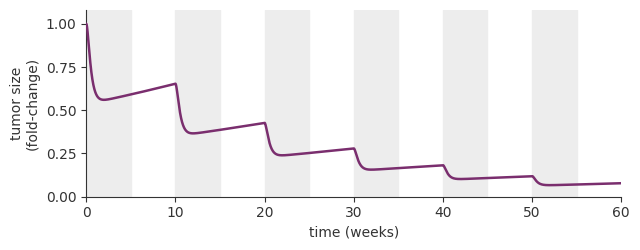

In [37]:
# --- Figure 1D: one drug, cycled on and off -------------------------------
# The same single feedback loop, with the drug applied in alternating blocks
# (shaded = on). While on, the blocked A->B arm drives B below setpoint and the
# tumor shrinks; adaptation closes the deficit and shrinkage stops, giving the
# within-block plateau. The off block lets A relax back to baseline, so the next
# on block opens a fresh deficit and the response repeats.
P, T_cyc = 5.0, 60.0            # weeks per block, total span
c1_cyc, c2_cyc = 0.02, 2.5      # growth and kill rates on this longer schedule


def rhs_cyc(s, y):
    A, B, C = y
    on = 1.0 if (s // P) % 2 == 0 else 0.0
    return [alpha * (mu - B),
            beta1 * (1 - e * on) * A - beta2 * B,
            C * (c1_cyc - c2_cyc * on * max(mu - B, 0.0))]


t_cyc = np.linspace(0, T_cyc, 6000)
A_cyc, B_cyc, C_cyc = solve_ivp(rhs_cyc, [0, T_cyc],
                                [beta2 * mu / beta1, mu, 1.0],
                                max_step=0.005, dense_output=True).sol(t_cyc)

fig, ax = plt.subplots(figsize=(6.5, 2.6))
for k in range(0, int(T_cyc // P), 2):          # shade the on blocks
    ax.axvspan(k * P, (k + 1) * P, color='0.93', zorder=0)
ax.plot(t_cyc, C_cyc, color=TUMOR, lw=1.8, zorder=3)
ax.set_xlim(0, T_cyc)
ax.set_ylim(0, 1.08)
ax.set_xticks(range(0, int(T_cyc) + 1, 10))
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_xlabel('time (weeks)')
ax.set_ylabel('tumor size\n(fold-change)')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
save_fig(fig, "Figure1_D")